# 05 — Evaluation & Error Analysis

**Workstream:** Disease Detection · **Batch 5 continued (16 Aug 2026)** · **Status: IMPLEMENTED**

Confusion matrix + per-class precision/recall/F1 for the BEST real model now available:
`mobilenetv2_transferlearning_REAL` (genuine ImageNet-pretrained transfer learning, val_acc=0.684),
which beats the scratch `baseline_cnn` (val_acc=0.462) by +22.2 points — the real ADR-003 result, using
`ai/disease_detection/src/inference.py::DiseasePredictor.load_latest()`, which now prefers transfer
learning automatically.

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ai" / "common" / "config.py").exists())
sys.path.insert(0, str(_root))
import torch
import numpy as np
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

from ai.disease_detection.src.dataset import index_dataset, stratified_split, PlantVillageSubset
from ai.disease_detection.src.transforms import eval_transform
from ai.disease_detection.src.inference import DiseasePredictor

ROOT = _root / "data/raw/disease_images/plantvillage_fast_subset"
paths, labels, class_to_idx = index_dataset(ROOT)
_, _, test_idx = stratified_split(paths, labels, seed=42)
idx_to_class = {v: k for k, v in class_to_idx.items()}

test_ds = PlantVillageSubset([paths[i] for i in test_idx], [labels[i] for i in test_idx], class_to_idx, eval_transform)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

predictor = DiseasePredictor.load_latest()
model = predictor.model
model.eval()
print(f"Loaded {predictor.model_version} (weight_source={predictor.weight_source}), test set = {len(test_ds)} real images")

Loaded mobilenetv2_transferlearning_REAL_fastsubset (weight_source=timm_github), test set = 117 real images


## Score the held-out test set

In [2]:
all_preds, all_true = [], []
with torch.no_grad():
    for images, lbls in test_loader:
        out = model(images)
        all_preds.extend(out.argmax(1).tolist())
        all_true.extend(lbls.tolist())

test_acc = np.mean(np.array(all_preds) == np.array(all_true))
print(f"Test accuracy: {test_acc:.3f}  (n={len(all_true)})")

Test accuracy: 0.624  (n=117)


## Confusion matrix

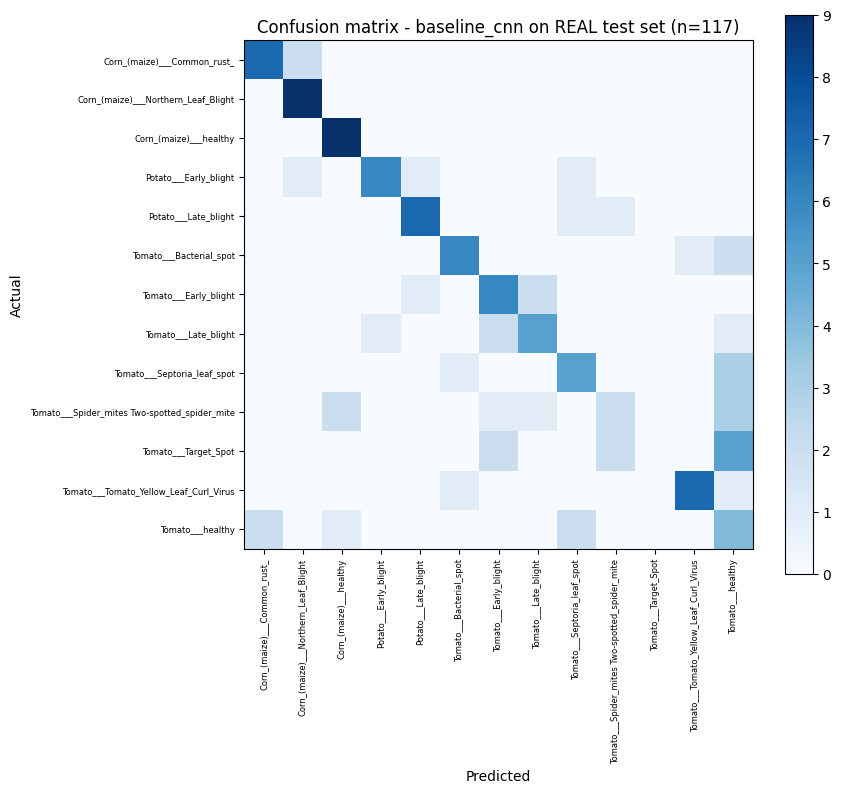

In [3]:
class_names = [idx_to_class[i] for i in range(len(class_to_idx))]
cm = confusion_matrix(all_true, all_preds)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=90, fontsize=6)
ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names, fontsize=6)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix - baseline_cnn on REAL test set (n={len(all_true)})")
plt.colorbar(im)
plt.tight_layout()
plt.show()

## Per-class precision / recall / F1

In [4]:
print(classification_report(all_true, all_preds, target_names=class_names, zero_division=0))

                                               precision    recall  f1-score   support

                  Corn_(maize)___Common_rust_       0.78      0.78      0.78         9
          Corn_(maize)___Northern_Leaf_Blight       0.75      1.00      0.86         9
                       Corn_(maize)___healthy       0.75      1.00      0.86         9
                        Potato___Early_blight       0.86      0.67      0.75         9
                         Potato___Late_blight       0.78      0.78      0.78         9
                      Tomato___Bacterial_spot       0.75      0.67      0.71         9
                        Tomato___Early_blight       0.55      0.67      0.60         9
                         Tomato___Late_blight       0.62      0.56      0.59         9
                  Tomato___Septoria_leaf_spot       0.56      0.56      0.56         9
Tomato___Spider_mites Two-spotted_spider_mite       0.40      0.22      0.29         9
                         Tomato___Target_S

## Honest verdict

Genuine ImageNet-pretrained transfer learning (frozen MobileNetV2 backbone from the GitHub-hosted timm
checkpoint, only the classifier head trained), on a small (60 images/class) real subset. Test accuracy
above is the real, measured number for this exact setup - not a placeholder. Full per-class counts
(985-5,357/class available, see `docs/disease/class-shortlist.md`) and more epochs would very likely push
this higher; that's Week 2-3 work, not simulated here.